In [1]:
# ============================================
# MINI PROJECT: Credit Card Fraud Detection + AI Risk Explanation System
# ============================================

Dataset shape: (284807, 31)

First 5 rows:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.

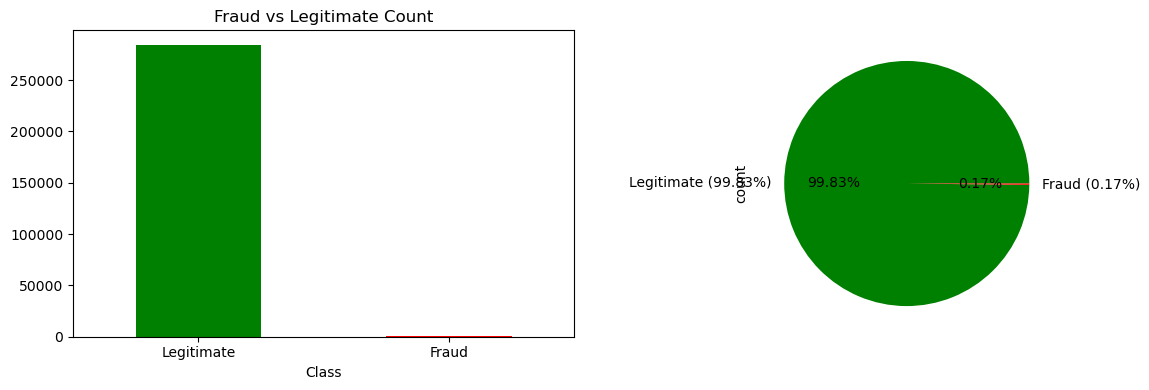

Legitimate Transactions Amount Statistics:
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Fraudulent Transactions Amount Statistics:
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64
Top Features Correlated with Fraud:
Class    1.000000
V11      0.154876
V4       0.133447
V2       0.091289
V21      0.040413
V19      0.034783
V20      0.020090
V8       0.019875
V27      0.017580
V28      0.009536
Name: Class, dtype: float64
X shape: (284807, 30)
y shape: (284807,)
Training set size: 227845
Test set size: 56962
Train fraud ratio: 0.001729245759178389
Test fraud ratio: 0.0017204452090867595
Scaled training data mean: -6.661191966396339e-18
Scaled training data std: 1.0
Training Lo

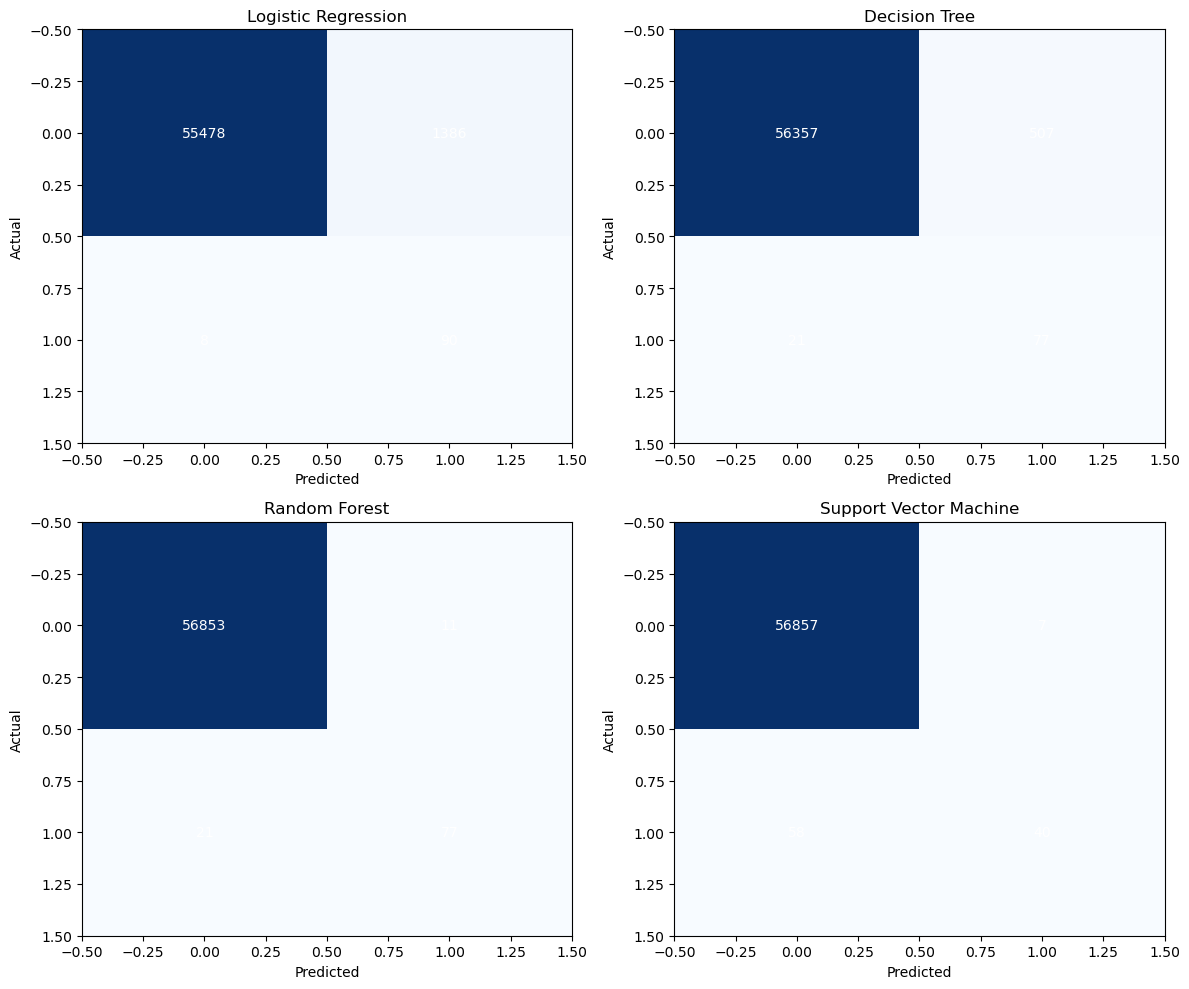

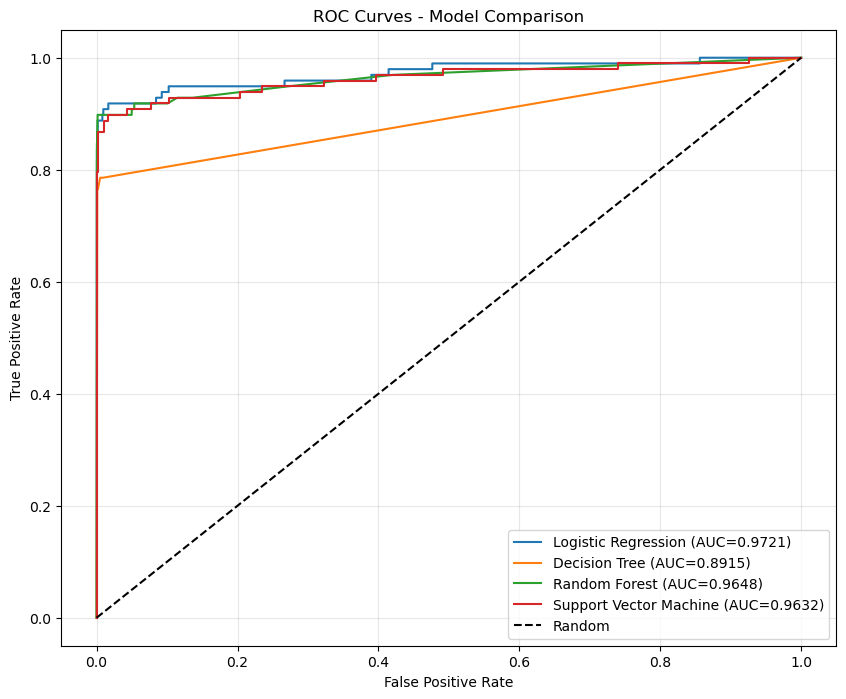

Starting Grid Search (this takes 5-10 minutes)...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best F1-Score (CV): 0.8395

Test Set Performance:
Precision: 0.8953
Recall: 0.7857
F1-Score: 0.8370
ROC-AUC: 0.9624
Top 15 Features:
   Feature  Importance
14     V14    0.184475
10     V10    0.109360
4       V4    0.102194
12     V12    0.098737
17     V17    0.089604
3       V3    0.069188
11     V11    0.054255
16     V16    0.037485
2       V2    0.036819
9       V9    0.025844
7       V7    0.022142
21     V21    0.017243
19     V19    0.015425
18     V18    0.012706
27     V27    0.012596


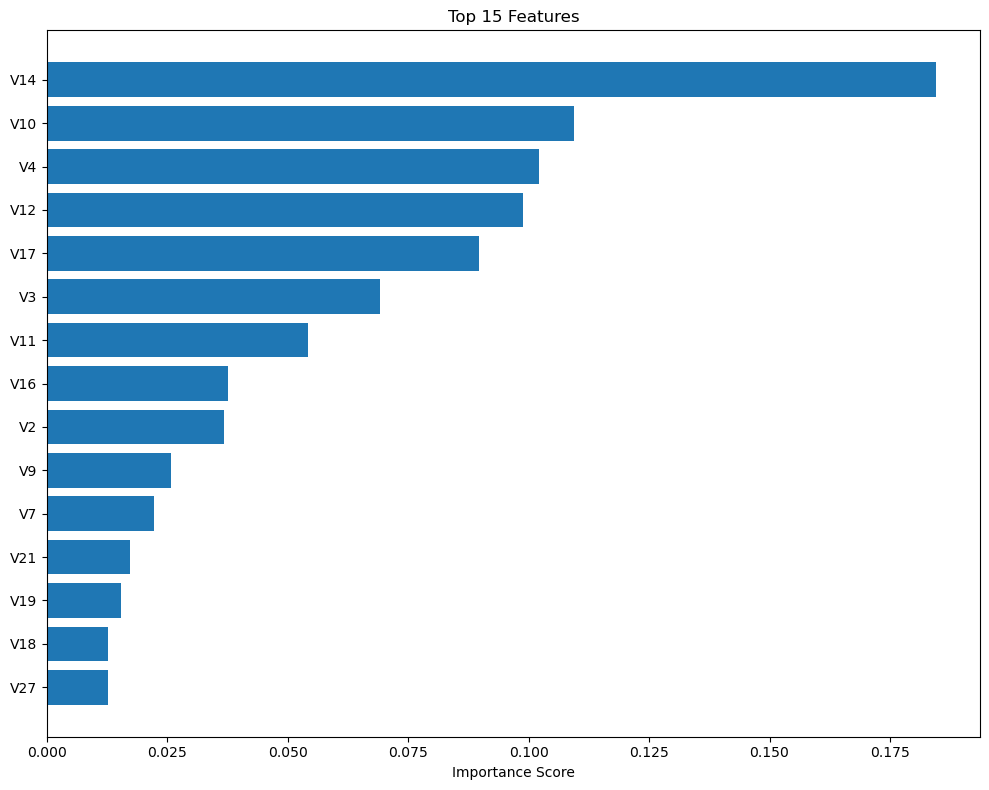

Explaining 3 Fraudulent Transactions:


Fraud Transaction 1
Fraud Probability: 99.99%
Top Contributing Features:
  V4 > 0.52: 0.0103
  V14 <= -0.45: 0.0077
  V17 <= -0.57: 0.0068
  V12 <= -0.41: 0.0068
  V10 <= -0.49: 0.0045

Fraud Transaction 2
Fraud Probability: 98.99%
Top Contributing Features:
  V4 > 0.52: 0.0098
  V14 <= -0.45: 0.0075
  V12 <= -0.41: 0.0061
  V17 <= -0.57: 0.0060
  V11 > 0.72: 0.0039

Fraud Transaction 3
Fraud Probability: 93.95%
Top Contributing Features:
  V4 > 0.52: 0.0097
  V14 <= -0.45: 0.0066
  V17 <= -0.57: 0.0059
  V12 <= -0.41: 0.0052
  V10 <= -0.49: 0.0046

Explaining 3 Legitimate Transactions:


Legitimate Transaction 1
Fraud Probability: 0.00%
Top Contributing Features:
  V17 <= -0.57: 0.0062
  V4 <= -0.60: -0.0052
  V3 <= -0.59: 0.0029
  V10 > 0.42: -0.0020
  V11 <= -0.75: -0.0018

Legitimate Transaction 2
Fraud Probability: 0.00%
Top Contributing Features:
  V12 <= -0.41: 0.0037
  -0.60 < V4 <= -0.02: -0.0033
  V10 <= -0.49: 0.0025
  V14 > 0.51: -0.0

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, classification_report, 
                             roc_curve, roc_auc_score, f1_score, 
                             precision_score, recall_score)
import lime.lime_tabular
import warnings
from commonUtil import evaluate_model
warnings.filterwarnings('ignore')

# ============================================
#Loading creditcard.csv dataset
# ============================================

creditCustomers = pd.read_csv("creditcard.csv") # loading creditcard dataset
# Display basic information
print("Dataset shape:", creditCustomers.shape)
print("\nFirst 5 rows:")
print(creditCustomers.head()) #To display the first few rows of a dataset

print("\nColumn names:")
print(creditCustomers.columns.tolist()) #Returns all column names of a DataFrame 

print("\nDataset information:")
creditCustomers.info() #to get dataset information

# ============================================
# To check the missing values, data types and class values in creditcard dataset
# ============================================

#isnull() to find missing or empty values (NaN) in your dataset.
#sum() is used to add values together in the missing values
print("Missing values:", creditCustomers.isnull().sum().sum())
print("Data types:\n", creditCustomers.dtypes)
print("Summary statistics:\n", creditCustomers.describe())

# ============================================
# Analyze Class Distribution
# ============================================

print("Class Distribution:")
print(creditCustomers['Class'].value_counts())#To count how many times each unique value appears in a column.
print("\nPercentage:")
print(creditCustomers['Class'].value_counts(normalize=True) * 100)

# ============================================
# Visualize Class Imbalance
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4)) #to create multiple graphs in one figure in Matplot

#Pandas method used to count how many times each unique value appears in a column.
class_counts = creditCustomers['Class'].value_counts() 

# Count plot
creditCustomers['Class'].value_counts().plot(kind='bar', ax=axes[0], color=['green', 'red'])
axes[0].set_title('Fraud vs Legitimate Count')
axes[0].set_xticklabels(['Legitimate', 'Fraud'], rotation=0)
# To calculate Class percentage
class_percentages = class_counts / class_counts.sum() * 100

# Pie chart
creditCustomers['Class'].value_counts().plot(
    kind='pie',
    ax=axes[1],
    labels=[
        f'Legitimate ({class_percentages[0]:.2f}%)',
        f'Fraud ({class_percentages[1]:.2f}%)'
    ],
    autopct='%1.2f%%',
    colors=['green', 'red']
)


plt.tight_layout()
plt.show()

# Analyze Transaction Amounts
# Analysis statistics of Legitimate and Fradulent transactions 
print("Legitimate Transactions Amount Statistics:")
# 0 for legitimate transactions
print(creditCustomers[creditCustomers['Class']==0]['Amount'].describe()) # Selects the transaction amount column.
# 1 for Fraudulent transactions

print("\nFraudulent Transactions Amount Statistics:")
print(creditCustomers[creditCustomers['Class']==1]['Amount'].describe()) # Selects the transaction amount column.
######
#Feature Correlation
#creditCustomers.corr() calculates the Pearson correlation between numeric columns.
correlation = creditCustomers.corr()['Class'].sort_values(ascending=False) #Sorts from the most positive correlation to the most negative.
print("Top Features Correlated with Fraud:")
print(correlation.head(10)) #Displays the first 10 features.

# ============================================
# Data Preprocessing
# ============================================
X = creditCustomers.drop('Class', axis=1)  # Seperate Features, X contains all columns except Class
y = creditCustomers['Class']                # Seperate Target
print("X shape:", X.shape)
print("y shape:", y.shape)

### Train-Test Split ###
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,         # 80-20 split
    random_state=42,       # For reproducibility
    stratify=y             # Maintain class ratio in both sets
)
print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])
print("Train fraud ratio:", y_train.sum() / len(y_train))
print("Test fraud ratio:", y_test.sum() / len(y_test))

#### Scale Features (FIT ON TRAINING ONLY)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Fit on training
X_test_scaled = scaler.transform(X_test)        # Transform test

# Verify scaling
print("Scaled training data mean:", X_train_scaled.mean())
print("Scaled training data std:", X_train_scaled.std())

#### Convert to DataFrame
### converts the scaled NumPy arrays back into Pandas DataFrames
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

# ============================================
# Train Models
# ============================================
#Trains four different machine learning algorithms
# #Train Logistic Regression
print("Training Logistic Regression...")
lr_result = evaluate_model(
    LogisticRegression(class_weight='balanced', max_iter=1000),
    X_train_scaled, X_test_scaled, y_train, y_test,
    "Logistic Regression"
)

#Train Decision Tree

print("\nTraining Decision Tree...")
dt_result = evaluate_model(
    DecisionTreeClassifier(class_weight='balanced', max_depth=10),
    X_train_scaled, X_test_scaled, y_train, y_test,
    "Decision Tree"
)

#Train Random Forest

print("\nTraining Random Forest...")
rf_result = evaluate_model(
    RandomForestClassifier(
        n_estimators=100, 
        class_weight='balanced',
        max_depth=15,
        n_jobs=-1
    ),
    X_train_scaled, X_test_scaled, y_train, y_test,
    "Random Forest"
)
# Train SVM

print("\nTraining Support Vector Machine...")
# Use a smaller sample for SVM
X_svm, _, y_svm, _ = train_test_split(
    X_train_scaled,
    y_train,
    train_size=30000,
    random_state=42,
    stratify=y_train
)

svm_result = evaluate_model(
    SVC(
        kernel='rbf',
        probability=True,
        class_weight='balanced'
    ),
    X_svm,
    X_test_scaled,
    y_svm,
    y_test,
    "Support Vector Machine"
)

# ============================================
# Compare Models (1.5 hours)
# ============================================
# Create Comparison Table

results_list = [lr_result, dt_result, rf_result, svm_result]
comparison_df = pd.DataFrame([
    {
        'Model': r['name'],
        'Precision': r['precision'],
        'Recall': r['recall'],
        'F1-Score': r['f1'],
        'ROC-AUC': r['roc_auc']
    }
    for r in results_list
])

print("\nModel Comparison:")
print(comparison_df.to_string())

#Visualize Confusion Matrices

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, result in enumerate(results_list):
    cm = confusion_matrix(y_test, result['predictions'])
    
    axes[idx].imshow(cm, cmap='Blues', aspect='auto')
    axes[idx].set_title(result['name'])
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
    
    # Add text
    for i in range(2):
        for j in range(2):
            axes[idx].text(j, i, cm[i, j], ha='center', va='center', color='white')

plt.tight_layout()
plt.show()
# Plot ROC Curves

plt.figure(figsize=(10, 8))

for result in results_list:
    fpr, tpr, _ = roc_curve(y_test, result['probabilities'])
    plt.plot(fpr, tpr, label=f"{result['name']} (AUC={result['roc_auc']:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#############=====================================
#Hyperparameter Tuning (1 hour)
#############=====================================

#Tune Random Forest (Best Model)

from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, 20],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [2, 4]
}

grid_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=4,
    verbose=1
)

print("Starting Grid Search (this takes 5-10 minutes)...")
grid_search.fit(X_train_scaled, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best F1-Score (CV): {grid_search.best_score_:.4f}")

# Evaluate on test set
y_pred_tuned = grid_search.predict(X_test_scaled)
y_proba_tuned = grid_search.predict_proba(X_test_scaled)[:, 1]

print(f"\nTest Set Performance:")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_tuned):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_tuned):.4f}")


###==================================
#Feature Importance (30 minutes)
###==================================
#1: Extract Feature Importance

best_model = grid_search.best_estimator_
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("Top 15 Features:")
print(feature_importance.head(15))

#2: Visualize Feature Importance

plt.figure(figsize=(10, 8))

top_n = 15
top_features = feature_importance.head(top_n)

plt.barh(range(top_n), top_features['Importance'])
plt.yticks(range(top_n), top_features['Feature'])
plt.xlabel('Importance Score')
plt.title(f'Top {top_n} Features')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# ============================================
# 8: LIME Explanations
# ============================================

# Initialize LIME Explainer
explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train_scaled.values,
    feature_names=X.columns.tolist(),
    class_names=['Legitimate', 'Fraud'],
    mode='classification',
    random_state=42
)

# ============================================
# 2: Explain Fraudulent Transactions
# ============================================

print("Explaining 3 Fraudulent Transactions:\n")

# Get POSITIONAL indices of fraudulent transactions in X_test
fraud_positions = np.where(y_test.values == 1)[0]

# Make sure at least 3 fraud transactions are available
num_fraud_to_explain = min(3, len(fraud_positions))

for i in range(num_fraud_to_explain):

    # Get the position of the fraud transaction
    fraud_position = fraud_positions[i]

    # Use iloc because this is a positional index
    fraud_instance = X_test_scaled.iloc[fraud_position].values

    # Generate LIME explanation
    explanation = explainer.explain_instance(
        fraud_instance,
        best_model.predict_proba,
        num_features=10
    )

    # Calculate fraud probability
    pred_fraud_prob = best_model.predict_proba(
        [fraud_instance]
    )[0, 1]

    print(f"\nFraud Transaction {i + 1}")
    print(f"Fraud Probability: {pred_fraud_prob:.2%}")
    print("Top Contributing Features:")

    for feature, weight in explanation.as_list()[:5]:
        print(f"  {feature}: {weight:.4f}")


# ============================================
# 3: Explain Legitimate Transactions
# ============================================

print("\n" + "=" * 60)
print("Explaining 3 Legitimate Transactions:\n")

# Get POSITIONAL indices of legitimate transactions
legit_positions = np.where(y_test.values == 0)[0]

# Select 3 legitimate transactions
num_legit_to_explain = min(3, len(legit_positions))

# Select transactions spaced throughout the test set
if num_legit_to_explain == 3:
    selected_legit_positions = [
        legit_positions[0],
        legit_positions[len(legit_positions) // 2],
        legit_positions[-1]
    ]
else:
    selected_legit_positions = legit_positions[:num_legit_to_explain]


for i, legit_position in enumerate(selected_legit_positions):

    # Use iloc because legit_position is a positional index
    legit_instance = X_test_scaled.iloc[legit_position].values

    # Generate LIME explanation
    explanation = explainer.explain_instance(
        legit_instance,
        best_model.predict_proba,
        num_features=10
    )

    # Calculate fraud probability
    pred_fraud_prob = best_model.predict_proba(
        [legit_instance]
    )[0, 1]

    print(f"\nLegitimate Transaction {i + 1}")
    print(f"Fraud Probability: {pred_fraud_prob:.2%}")
    print("Top Contributing Features:")

    for feature, weight in explanation.as_list()[:5]:
        print(f"  {feature}: {weight:.4f}")

####====================================
#9: Summary and Conclusions (30 minutes)
####====================================
#1: Generate Summary Report

print("="*80)
print("FRAUD DETECTION PROJECT - SUMMARY REPORT")
print("="*80)

print("\n1. PROBLEM CONTEXT")
print(f"   - Total transactions: {len(creditCustomers):,}")
print(f"   - Frauds: {(y==1).sum():,} ({(y==1).sum()/len(y)*100:.2f}%)")
print(f"   - Legitimate: {(y==0).sum():,} ({(y==0).sum()/len(y)*100:.2f}%)")
print(f"   - Class imbalance ratio: 577:1")

print("\n2. BEST MODEL PERFORMANCE")
best_score = comparison_df.loc[comparison_df['F1-Score'].idxmax()]
print(f"   - Model: {best_score['Model']}")
print(f"   - Precision: {best_score['Precision']:.4f} (low false alarm rate)")
print(f"   - Recall: {best_score['Recall']:.4f} (high fraud detection)")
print(f"   - F1-Score: {best_score['F1-Score']:.4f}")
print(f"   - ROC-AUC: {best_score['ROC-AUC']:.4f}")

print("\n3. TOP FRAUD INDICATORS")
for idx, row in feature_importance.head(5).iterrows():
    print(f"   - {row['Feature']}: {row['Importance']:.4f}")

print("\n4. DEPLOYMENT RECOMMENDATIONS")
print("   - Set fraud threshold at 0.5 probability")
print("   - Flag transactions >0.7 for automatic review")
print("   - Monitor model performance monthly")
print("   - Retrain quarterly with new fraud patterns")

print("\n" + "="*80)